# MS COCO multi-label classification: transfer learning challenge

This notebook is the complete, reproducible submission for the course challenge. It uses **only the adapted course MS COCO archive** for supervised training and the ImageNet-pretrained TorchVision weights for transfer learning. No other MS COCO distribution or test labels are used.

**Protocol.** We make one fixed 80/20 split of the 65,000 labelled images. Three predeclared transfer-learning approaches use exactly this split. We select checkpoints and one global probability threshold **using validation data only**. The 4,952 unlabelled test images are used only after model selection, to produce the required JSON prediction files. Any optional evaluation-server scores are for the final report; they must not change model selection or hyperparameters. We do not update the public leaderboard from this notebook.

The experiments compare (A) a frozen ResNet-18 feature extractor, (B) a frozen MobileNetV3-Large feature extractor, and (C) a staged ResNet-18 with its final residual block unfrozen. This distinguishes architecture choice from the effect of limited fine-tuning. All code required to reproduce the experiment is in this file; model checkpoints and prediction files are saved separately to Google Drive for durability.


## 1. Environment, reproducibility and output location

Run this notebook in a Colab **GPU** runtime. Google Drive is mounted to preserve checkpoints and results across Colab sessions; the dataset itself is extracted to the runtime's local disk because reading tens of thousands of small files through a Drive mount is slow. The random seed, split, library versions and accelerator are recorded below. Runtime hardware and TorchVision versions can change the exact scores.


In [ ]:
import json, os, random, shutil, subprocess, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torchvision
from google.colab import drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Select Runtime > Change runtime type > GPU before training.'
drive.mount('/content/drive')
OUT_DIR = Path('/content/drive/MyDrive/IAV_MS_COCO')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ("person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat", "traffic light",
           "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
           "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
           "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove", "skateboard", "surfboard",
           "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
           "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch",
           "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse", "remote", "keyboard", "cell phone",
           "microwave", "oven", "toaster", "sink", "refrigerator", "book", "clock", "vase", "scissors", "teddy bear",
           "hair drier", "toothbrush")
NUM_CLASSES = len(CLASSES)
print('Python/PyTorch/TorchVision:', os.sys.version.split()[0], torch.__version__, torchvision.__version__)
print('Accelerator:', torch.cuda.get_device_name(0))
print('Drive output folder:', OUT_DIR)


Mounted at /content/drive
Python/PyTorch/TorchVision: 3.13.15 2.11.0+cu130 0.26.0+cu130
Accelerator: Tesla T4
Drive output folder: /content/drive/MyDrive/IAV_MS_COCO


## 2. Acquire and verify the permitted dataset

The course archive is approximately 1.84 GB. This cell reuses an intact copy already in `/content` and otherwise downloads it directly from the course server. It checks ZIP integrity before extracting. The checks at the end establish the exact folder paths and expected image counts; no other COCO source is involved.


In [ ]:
DATA_URL = 'https://www.creatis.insa-lyon.fr/~kechichian/IAV/ms-coco.zip'
ARCHIVE = Path('/content/ms-coco.zip')
DATA_ROOT = Path('/content/data/ms-coco')
TRAIN_IMAGE_DIR = DATA_ROOT / 'images/train'
TRAIN_LABEL_DIR = DATA_ROOT / 'labels/train'
TEST_IMAGE_DIR = DATA_ROOT / 'images/test'
EXPECTED_ARCHIVE_BYTES = 1_836_661_512  # observed from the course server on 8 October 2026

already_extracted = (TRAIN_IMAGE_DIR.exists() and TRAIN_LABEL_DIR.exists() and TEST_IMAGE_DIR.exists()
                     and len(list(TRAIN_IMAGE_DIR.glob('*.jpg'))) == 65_000
                     and len(list(TRAIN_LABEL_DIR.glob('*.cls'))) == 65_000
                     and len(list(TEST_IMAGE_DIR.glob('*.jpg'))) == 4_952)
if not already_extracted:
    if not ARCHIVE.exists() or ARCHIVE.stat().st_size != EXPECTED_ARCHIVE_BYTES:
        subprocess.run(['wget', '-c', '--progress=dot:giga', '-O', str(ARCHIVE), DATA_URL], check=True)
    assert ARCHIVE.stat().st_size == EXPECTED_ARCHIVE_BYTES, 'Unexpected archive size; check the download.'
    with zipfile.ZipFile(ARCHIVE) as zf:
        assert zf.testzip() is None, 'ZIP checksum validation failed.'
        zf.extractall('/content/data')

train_files = sorted(TRAIN_IMAGE_DIR.glob('*.jpg'))
test_files = sorted(TEST_IMAGE_DIR.glob('*.jpg'))
label_files = sorted(TRAIN_LABEL_DIR.glob('*.cls'))
assert len(train_files) == len(label_files) == 65_000
assert len(test_files) == 4_952
assert {p.stem for p in train_files} == {p.stem for p in label_files}
print('Train images / label files / test images:', len(train_files), len(label_files), len(test_files))
print('Example image:', train_files[0].name, 'labels:', (TRAIN_LABEL_DIR / (train_files[0].stem + '.cls')).read_text().split())
print('Free local disk (GiB):', round(shutil.disk_usage('/content').free / 2**30, 1))


Train images / label files / test images: 65000 65000 4952
Example image: 000000000009.jpg labels: ['45', '49', '50']
Free local disk (GiB): 66.3


## 3. Target matrix, fixed split and class imbalance

Each `.cls` file lists zero-based indices into the 80-class tuple. We convert it to a multi-hot vector. A fixed seeded split gives the same 52,000 training and 13,000 validation images to every method. Class frequencies are computed from the training portion only. Rare positive labels receive a capped positive loss weight; the cap prevents a handful of very rare classes from dominating optimization.


In [ ]:
image_paths = train_files
targets = np.zeros((len(image_paths), NUM_CLASSES), dtype=np.float32)
for i, path in enumerate(image_paths):
    ids = [int(x) for x in (TRAIN_LABEL_DIR / (path.stem + '.cls')).read_text().split()]
    assert all(0 <= x < NUM_CLASSES for x in ids)
    targets[i, ids] = 1.0

permutation = np.random.default_rng(SEED).permutation(len(image_paths))
split_at = int(0.8 * len(permutation))
train_indices = permutation[:split_at].tolist()
val_indices = permutation[split_at:].tolist()
np.savez(OUT_DIR / 'split_seed42.npz', train_indices=train_indices, val_indices=val_indices)
train_count = targets[train_indices].sum(axis=0)
val_count = targets[val_indices].sum(axis=0)
assert np.all(train_count > 0) and np.all(val_count > 0), 'A class is absent; reconsider the split.'
pos_weight = np.clip((len(train_indices) - train_count) / np.maximum(train_count, 1), 1, 20)
class_counts = pd.DataFrame({'class_id': np.arange(NUM_CLASSES), 'class_name': CLASSES,
                             'train_positives': train_count.astype(int), 'val_positives': val_count.astype(int),
                             'loss_pos_weight': pos_weight.round(2)})
display(class_counts.sort_values('train_positives').head(10))
print('Train/validation:', len(train_indices), len(val_indices))
print('Mean labels per image:', round(float(targets.sum(axis=1).mean()), 3))


,class_id,class_name,train_positives,val_positives,loss_pos_weight
78,78,hair drier,76,26,20.0
70,70,toaster,97,20,20.0
12,12,parking meter,335,61,20.0
21,21,bear,414,102,20.0
76,76,scissors,445,110,20.0
79,79,toothbrush,452,109,20.0
52,52,hot dog,534,133,20.0
18,18,sheep,647,162,20.0
68,68,microwave,677,155,20.0
54,54,donut,690,166,20.0


Train/validation: 52000 13000
Mean labels per image: 2.926


## 4. Image preprocessing and data loaders

Images have different aspect ratios. Resizing the full image to 224×224 keeps every annotated object in view, at the cost of some aspect-ratio distortion. Horizontal flipping is the only training augmentation: aggressive random crops could remove a labelled object while retaining its label. Validation and test use deterministic preprocessing. ImageNet normalization matches the pretrained backbones.


In [ ]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                     transforms.Normalize(MEAN, STD)])

class LabeledCOCO(Dataset):
    def __init__(self, paths, target_matrix, indices, transform):
        self.paths, self.target_matrix, self.indices, self.transform = paths, target_matrix, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, item):
        index = self.indices[item]
        with Image.open(self.paths[index]) as image:
            pixels = self.transform(image.convert('RGB'))
        return pixels, torch.from_numpy(self.target_matrix[index])

class UnlabeledCOCO(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, item):
        path = self.paths[item]
        with Image.open(path) as image:
            pixels = self.transform(image.convert('RGB'))
        return pixels, path.stem

train_dataset = LabeledCOCO(image_paths, targets, train_indices, train_transform)
val_dataset = LabeledCOCO(image_paths, targets, val_indices, eval_transform)
test_dataset = UnlabeledCOCO(test_files, eval_transform)
def make_loader(dataset, batch_size, shuffle=False):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=2,
                      pin_memory=True, persistent_workers=False)

sample_x, sample_y = train_dataset[0]
assert sample_x.shape == (3, 224, 224) and sample_y.shape == (80,)
print('Sample tensor / positive class IDs:', tuple(sample_x.shape), torch.where(sample_y > 0)[0].tolist())


Sample tensor / positive class IDs: (3, 224, 224) [0, 1, 2, 7, 26, 36]


## 5. Transfer-learning models and multi-label objective

Each pretrained classifier is replaced by an 80-logit head. A and B train only that new head. C starts from A's selected checkpoint and unfreezes ResNet-18's final residual block as a second training stage. BatchNorm running statistics remain fixed, avoiding drift during limited fine-tuning. `BCEWithLogitsLoss` independently models each class; sigmoid is applied only to turn logits into probabilities for thresholding. A softmax/argmax would be incorrect for multiple labels.


In [ ]:
def build_model(architecture, pretrained=True):
    if architecture == 'resnet18':
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        net = models.resnet18(weights=weights)
        net.fc = nn.Linear(net.fc.in_features, NUM_CLASSES)
    elif architecture == 'mobilenet_v3_large':
        weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        net = models.mobilenet_v3_large(weights=weights)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, NUM_CLASSES)
    else:
        raise ValueError(architecture)
    return net

def prepare_model(experiment_key):
    if experiment_key == 'A_resnet18_frozen':
        net = build_model('resnet18')
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.fc.parameters(): parameter.requires_grad = True
    elif experiment_key == 'B_mobilenet_frozen':
        net = build_model('mobilenet_v3_large')
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.classifier[-1].parameters(): parameter.requires_grad = True
    elif experiment_key == 'C_resnet18_finetune':
        net = build_model('resnet18', pretrained=False)
        parent = torch.load(OUT_DIR / 'A_resnet18_frozen.pt', map_location='cpu', weights_only=False)
        net.load_state_dict(parent['state_dict'])
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.layer4.parameters(): parameter.requires_grad = True
        for parameter in net.fc.parameters(): parameter.requires_grad = True
    else:
        raise ValueError(experiment_key)
    return net.to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
print('Positive loss weights:', float(pos_weight.min()), 'to', float(pos_weight.max()))


Positive loss weights: 1.0 to 20.0


## 6. Validation metrics and threshold selection

The course evaluation emphasizes rare classes. Our primary selection metric is the harmonic mean of precision and recall after **inverse-frequency weighting by validation class frequency**, matching the provided validation-loop convention. We also report macro F1 (equal weight per class) and micro F1 (pooled decisions). Classes with no validation positives receive zero weight rather than an infinite weight. This is a multi-label metric: each class decision is independent.

For each epoch we sweep a small, predeclared grid of **global** sigmoid thresholds on validation data. No test labels or evaluation-server scores enter the search. A single global threshold limits tuning complexity compared with 80 separately fitted thresholds.


In [ ]:
THRESHOLDS = np.round(np.arange(0.10, 0.701, 0.05), 2)

def compute_metrics(truth, probabilities, threshold):
    actual = truth >= 0.5
    predicted = probabilities >= threshold
    tp = np.logical_and(predicted, actual).sum(axis=0).astype(float)
    fp = np.logical_and(predicted, ~actual).sum(axis=0).astype(float)
    fn = np.logical_and(~predicted, actual).sum(axis=0).astype(float)
    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    class_f1 = np.divide(2 * precision * recall, precision + recall,
                         out=np.zeros_like(tp), where=(precision + recall) > 0)
    frequency = tp + fn
    inverse = np.divide(1.0, frequency, out=np.zeros_like(frequency), where=frequency > 0)
    weights = inverse / inverse.sum()
    weighted_precision = float(np.dot(weights, precision))
    weighted_recall = float(np.dot(weights, recall))
    weighted_f1 = (2 * weighted_precision * weighted_recall / (weighted_precision + weighted_recall)
                   if weighted_precision + weighted_recall else 0.0)
    micro_precision = tp.sum() / max(tp.sum() + fp.sum(), 1)
    micro_recall = tp.sum() / max(tp.sum() + fn.sum(), 1)
    micro_f1 = (2 * micro_precision * micro_recall / (micro_precision + micro_recall)
                if micro_precision + micro_recall else 0.0)
    return {'weighted_f1': weighted_f1, 'weighted_precision': weighted_precision,
            'weighted_recall': weighted_recall, 'macro_f1': float(class_f1.mean()),
            'micro_f1': float(micro_f1), 'class_f1': class_f1,
            'class_precision': precision, 'class_recall': recall}

def choose_threshold(truth, probabilities):
    candidates = [(float(t), compute_metrics(truth, probabilities, float(t))) for t in THRESHOLDS]
    return max(candidates, key=lambda item: item[1]['weighted_f1'])


## 7. Training and validation loops

Mixed precision accelerates CUDA training. Validation uses `eval()` and inference mode. The training loop saves the highest-validation-F1 checkpoint for each approach to Drive, along with its validation-chosen threshold and full epoch history. Early stopping uses only validation performance. Training loss is shown as an optimization diagnostic; it is not used to choose the final method.


In [ ]:
def train_one_epoch(net, loader, optimizer, scaler):
    net.train()
    for module in net.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()  # preserve ImageNet running mean/variance
    total_loss, total_images = 0.0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.detach()) * len(images)
        total_images += len(images)
    return total_loss / total_images

@torch.inference_mode()
def evaluate(net, loader):
    net.eval()
    losses, probabilities, truths, total_images = 0.0, [], [], 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
            loss = criterion(logits, labels)
        losses += float(loss) * len(images)
        total_images += len(images)
        probabilities.append(torch.sigmoid(logits.float()).cpu().numpy())
        truths.append(labels.cpu().numpy())
    return losses / total_images, np.concatenate(probabilities), np.concatenate(truths)

def run_experiment(spec):
    key = spec['key']
    net = prepare_model(key)
    if key == 'C_resnet18_finetune':
        optimizer = torch.optim.AdamW([{'params': net.layer4.parameters(), 'lr': 1e-4},
                                       {'params': net.fc.parameters(), 'lr': 3e-4}], weight_decay=1e-4)
    else:
        optimizer = torch.optim.AdamW((p for p in net.parameters() if p.requires_grad),
                                      lr=spec['lr'], weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda')
    train_loader = make_loader(train_dataset, spec['batch_size'], shuffle=True)
    val_loader = make_loader(val_dataset, spec['batch_size'])
    checkpoint_path = OUT_DIR / f'{key}.pt'
    best_f1, no_improvement, rows = -1.0, 0, []
    for epoch in range(1, spec['max_epochs'] + 1):
        started = time.time()
        train_loss = train_one_epoch(net, train_loader, optimizer, scaler)
        val_loss, probabilities, truth = evaluate(net, val_loader)
        threshold, metrics = choose_threshold(truth, probabilities)
        row = {'experiment': key, 'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
               'threshold': threshold, 'weighted_f1': metrics['weighted_f1'],
               'macro_f1': metrics['macro_f1'], 'micro_f1': metrics['micro_f1'],
               'minutes': (time.time() - started) / 60}
        rows.append(row)
        print(pd.DataFrame([row]).round(4).to_string(index=False), flush=True)
        if metrics['weighted_f1'] > best_f1 + 1e-4:
            best_f1, no_improvement = metrics['weighted_f1'], 0
            torch.save({'experiment': key, 'architecture': spec['architecture'], 'epoch': epoch,
                        'threshold': threshold, 'validation_metrics': {k: v for k, v in metrics.items() if not k.startswith('class_')},
                        'state_dict': net.state_dict(), 'seed': SEED}, checkpoint_path)
        else:
            no_improvement += 1
        pd.DataFrame(rows).to_csv(OUT_DIR / f'{key}_history.csv', index=False)
        if no_improvement >= 2:
            print('Early stopping after two epochs without validation improvement.')
            break
    del net, optimizer, scaler
    torch.cuda.empty_cache()
    return pd.DataFrame(rows)


## 8. Predeclared experiments

The list below is fixed **before** seeing any test evaluation. A and B compare distinct pretrained network architectures as frozen feature extractors. C measures whether fine-tuning the last ResNet-18 block after A improves the validation metric. All models use the same labels, split, loss, augmentation and threshold grid. The five-epoch budget and two-epoch early stopping suit a Colab GPU session; the saved history documents the actual number of epochs.


In [ ]:
EXPERIMENTS = [
    {'key': 'A_resnet18_frozen', 'architecture': 'resnet18', 'batch_size': 128, 'lr': 1e-3, 'max_epochs': 5},
    {'key': 'B_mobilenet_frozen', 'architecture': 'mobilenet_v3_large', 'batch_size': 128, 'lr': 1e-3, 'max_epochs': 5},
    {'key': 'C_resnet18_finetune', 'architecture': 'resnet18', 'batch_size': 64, 'lr': None, 'max_epochs': 5},
]
histories = {}
for spec in EXPERIMENTS:
    print('\nStarting', spec['key'], flush=True)
    histories[spec['key']] = run_experiment(spec)



Starting A_resnet18_frozen
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      1      0.4829    0.4148       0.65       0.3898    0.4465    0.4892   2.6437
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      2      0.3978    0.4015        0.7       0.3952    0.4833    0.5224   2.5862
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      3      0.3824    0.3964        0.7       0.3965    0.4883    0.5299   2.4192
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      4      0.3735    0.3937        0.7       0.3967    0.4903    0.5323   2.4146
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      5      0.3681    0.3896        0.7       0.3906    0.4858    0.5243   2.4547


100%|██████████| 21.1M/21.1M [00:00<00:00, 154MB/s]


        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      1      0.4533    0.3656        0.7       0.4553    0.5345    0.5679   2.5075
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      2      0.3482     0.347        0.7       0.4522    0.5433    0.5759   2.4254
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      3      0.3279    0.3422        0.7       0.4507    0.5446    0.5788   2.4392
Early stopping after two epochs without validation improvement.

Starting C_resnet18_finetune
         experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
C_resnet18_finetune      1      0.3671    0.3645        0.7       0.4652    0.5092    0.5427   2.4904
         experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  mi

### Validation-only threshold calibration

The initial global grid (0.10–0.70) reached its upper boundary for all three saved checkpoints. Before test inference, we therefore apply the same expanded global grid (0.10–0.95 in steps of 0.025) to each checkpoint on the fixed validation split. This changes thresholds and reported validation metrics, but does not retrain models. The checkpoint epochs were selected using the initial grid; that is a limitation of this comparison. No test labels or evaluation-server scores inform this adjustment.

In [ ]:
CALIBRATION_THRESHOLDS = np.round(np.arange(0.10, 0.951, 0.025), 3)
for spec in EXPERIMENTS:
    key = spec['key']
    checkpoint_path = OUT_DIR / f'{key}.pt'
    saved = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    net = build_model(saved['architecture'], pretrained=False)
    net.load_state_dict(saved['state_dict'])
    net = net.to(DEVICE).eval()
    val_loss, probabilities, truth = evaluate(net, make_loader(val_dataset, 128))
    threshold, metrics = max(
        ((float(t), compute_metrics(truth, probabilities, float(t)))
         for t in CALIBRATION_THRESHOLDS),
        key=lambda pair: pair[1]['weighted_f1'])
    saved['threshold'] = threshold
    saved['validation_metrics'] = {k: v for k, v in metrics.items()
                                   if not k.startswith('class_')}
    saved['calibration_grid'] = '0.10 to 0.95, step 0.025; validation only'
    torch.save(saved, checkpoint_path)
    frame = histories[key]
    row_index = frame.index[frame['epoch'] == saved['epoch']][0]
    for column, value in {'threshold': threshold, 'weighted_f1': metrics['weighted_f1'],
                          'macro_f1': metrics['macro_f1'], 'micro_f1': metrics['micro_f1'],
                          'val_loss': val_loss}.items():
        frame.at[row_index, column] = value
    frame.to_csv(OUT_DIR / f'{key}_history.csv', index=False)
    print(key, 'checkpoint epoch:', saved['epoch'],
          'calibrated threshold:', threshold,
          'weighted F1:', round(metrics['weighted_f1'], 4), flush=True)
    del net
    torch.cuda.empty_cache()

A_resnet18_frozen checkpoint epoch: 4 calibrated threshold: 0.875 weighted F1: 0.4664
B_mobilenet_frozen checkpoint epoch: 1 calibrated threshold: 0.725 weighted F1: 0.4709
C_resnet18_finetune checkpoint epoch: 5 calibrated threshold: 0.875 weighted F1: 0.4957


## 9. Validation comparison and model selection

The table uses each approach's **best validation epoch** and its own validation-selected threshold. The primary rule, specified above, is maximum inverse-frequency-weighted validation F1. Macro and micro F1 show whether a gain on rare classes also improves overall decisions. The plots make loss trends and differences between approaches visible. The selected model and threshold are written to `selection.json` before any test prediction is generated.


,experiment,epoch,threshold,weighted_f1,macro_f1,micro_f1,val_loss
0,C_resnet18_finetune,5,0.875,0.4957,0.5854,0.6348,0.3800
1,B_mobilenet_frozen,1,0.725,0.4709,0.5442,0.5786,0.3656
2,A_resnet18_frozen,4,0.875,0.4664,0.5265,0.5711,0.3937


Selected from validation only: {'chosen_experiment': 'C_resnet18_finetune', 'selection_rule': 'highest validation inverse-frequency-weighted F1', 'validation_epoch': 5, 'validation_threshold': 0.875, 'seed': 42}


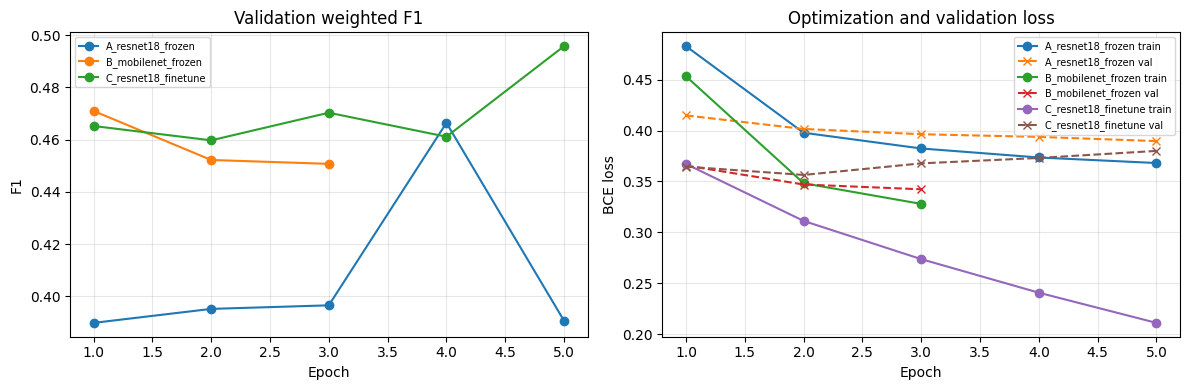

In [ ]:
history = pd.concat(histories.values(), ignore_index=True)
history.to_csv(OUT_DIR / 'all_experiments_history.csv', index=False)
best_rows = history.loc[history.groupby('experiment')['weighted_f1'].idxmax()].copy()
best_rows = best_rows.sort_values('weighted_f1', ascending=False).reset_index(drop=True)
display(best_rows[['experiment', 'epoch', 'threshold', 'weighted_f1', 'macro_f1', 'micro_f1', 'val_loss']].round(4))
winner = best_rows.iloc[0]['experiment']
selection = {'chosen_experiment': winner, 'selection_rule': 'highest validation inverse-frequency-weighted F1',
             'validation_epoch': int(best_rows.iloc[0]['epoch']),
             'validation_threshold': float(best_rows.iloc[0]['threshold']), 'seed': SEED}
(OUT_DIR / 'selection.json').write_text(json.dumps(selection, indent=2))
print('Selected from validation only:', selection)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, frame in history.groupby('experiment'):
    axes[0].plot(frame['epoch'], frame['weighted_f1'], marker='o', label=name)
    axes[1].plot(frame['epoch'], frame['train_loss'], marker='o', label=f'{name} train')
    axes[1].plot(frame['epoch'], frame['val_loss'], marker='x', linestyle='--', label=f'{name} val')
axes[0].set(title='Validation weighted F1', xlabel='Epoch', ylabel='F1')
axes[1].set(title='Optimization and validation loss', xlabel='Epoch', ylabel='BCE loss')
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'validation_comparison.png', dpi=150)
plt.show()


## 10. Per-class analysis of the selected model

The overall score can conceal uneven performance. This section reruns validation for the selected checkpoint and reports the ten best and worst classes by F1, together with their validation support. Rare classes often have noisier estimates; support should be considered when interpreting small differences. This is still validation analysis, not test-set tuning.


In [ ]:
def load_checkpoint(experiment_key):
    checkpoint = torch.load(OUT_DIR / f'{experiment_key}.pt', map_location='cpu', weights_only=False)
    net = build_model(checkpoint['architecture'], pretrained=False)
    net.load_state_dict(checkpoint['state_dict'])
    return net.to(DEVICE).eval(), checkpoint

selected_model, selected_checkpoint = load_checkpoint(winner)
selected_threshold = float(selected_checkpoint['threshold'])
selected_val_loss, selected_probs, selected_truth = evaluate(selected_model, make_loader(val_dataset, 128))
selected_metrics = compute_metrics(selected_truth, selected_probs, selected_threshold)
per_class = pd.DataFrame({'class_id': np.arange(NUM_CLASSES), 'class_name': CLASSES,
                          'val_support': selected_truth.sum(axis=0).astype(int),
                          'precision': selected_metrics['class_precision'],
                          'recall': selected_metrics['class_recall'],
                          'f1': selected_metrics['class_f1']})
per_class.to_csv(OUT_DIR / 'selected_model_per_class_validation.csv', index=False)
display(per_class.sort_values('f1').head(10).round(3))
display(per_class.sort_values('f1', ascending=False).head(10).round(3))
print('Selected validation weighted/macro/micro F1:',
      *(round(selected_metrics[key], 4) for key in ('weighted_f1', 'macro_f1', 'micro_f1')))
del selected_model
torch.cuda.empty_cache()


,class_id,class_name,val_support,precision,recall,f1
78,78,hair drier,26,0.500,0.038,0.071
70,70,toaster,20,0.120,0.150,0.133
76,76,scissors,110,0.333,0.282,0.305
24,24,backpack,619,0.319,0.326,0.323
79,79,toothbrush,109,0.375,0.330,0.351
67,67,cell phone,555,0.360,0.393,0.376
58,58,potted plant,470,0.385,0.404,0.394
12,12,parking meter,61,0.708,0.279,0.400
13,13,bench,626,0.473,0.372,0.416
47,47,apple,167,0.365,0.485,0.416


,class_id,class_name,val_support,precision,recall,f1
23,23,giraffe,290,0.941,0.941,0.941
22,22,zebra,222,0.939,0.901,0.920
0,0,person,7177,0.970,0.816,0.886
38,38,tennis racket,375,0.863,0.909,0.886
20,20,elephant,233,0.921,0.845,0.881
4,4,airplane,343,0.859,0.889,0.874
61,61,toilet,407,0.864,0.808,0.835
35,35,baseball glove,288,0.785,0.847,0.815
21,21,bear,102,0.856,0.755,0.802
30,30,skis,365,0.836,0.767,0.800


Selected validation weighted/macro/micro F1: 0.4957 0.5854 0.6348


## 11. Final test predictions and strict JSON export

Only after `selection.json` is fixed do we run inference on the unlabelled test subset. We export one JSON file per predeclared method so their final test metrics can be reported if desired; **the validation-selected winner remains unchanged**. Each key is the image stem (without `.jpg`) and each value is a list of zero-based class indices. The selected winner is additionally copied to `selected_test_predictions.json`. The JSON contains no comments or trailing commas.

The course evaluation page may be used in its *test-only* mode for reporting. Leave **“update leaderboard” unchecked** for all exploratory score requests. Test scores must not drive further model or threshold choices. A final public leaderboard update is intentionally outside this notebook.


In [ ]:
@torch.inference_mode()
def predict_test(net, threshold):
    predictions = {}
    for images, stems in make_loader(test_dataset, 128):
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
        is_positive = torch.sigmoid(logits.float()).cpu().numpy() >= threshold
        for stem, row in zip(stems, is_positive):
            predictions[str(stem)] = np.flatnonzero(row).astype(int).tolist()
    assert len(predictions) == len(test_dataset) == 4_952
    assert all(len(k) == 12 and all(0 <= c < NUM_CLASSES for c in values)
               for k, values in predictions.items())
    return predictions

for spec in EXPERIMENTS:
    key = spec['key']
    net, checkpoint = load_checkpoint(key)
    predictions = predict_test(net, float(checkpoint['threshold']))
    destination = OUT_DIR / f'{key}_test_predictions.json'
    destination.write_text(json.dumps(predictions, indent=2))
    print(key, '=>', destination, 'images:', len(predictions),
          'mean predicted labels:', round(np.mean([len(x) for x in predictions.values()]), 3))
    if key == winner:
        (OUT_DIR / 'selected_test_predictions.json').write_text(json.dumps(predictions, indent=2))
    del net
    torch.cuda.empty_cache()
print('Validation-selected JSON:', OUT_DIR / 'selected_test_predictions.json')


A_resnet18_frozen => /content/drive/MyDrive/IAV_MS_COCO/A_resnet18_frozen_test_predictions.json images: 4952 mean predicted labels: 2.547
B_mobilenet_frozen => /content/drive/MyDrive/IAV_MS_COCO/B_mobilenet_frozen_test_predictions.json images: 4952 mean predicted labels: 4.497
C_resnet18_finetune => /content/drive/MyDrive/IAV_MS_COCO/C_resnet18_finetune_test_predictions.json images: 4952 mean predicted labels: 2.926
Validation-selected JSON: /content/drive/MyDrive/IAV_MS_COCO/selected_test_predictions.json


### Optional course-server test-only evaluation

The validation-selected winner and thresholds are already fixed. The code below submits each of the three exported JSON files to the course evaluation endpoint with group name `just4test`. It sends the form's `name`, `descr`, `file` and `submit` fields only; **the `update` checkbox field is omitted**, so this is a test-only assessment and does not update the public leaderboard. These test results are descriptive and cannot alter model selection or thresholds. Re-running this cell makes three additional test-only requests.

In [ ]:
import requests
from bs4 import BeautifulSoup

EVAL_URL = 'https://www.creatis.insa-lyon.fr/kechichian/ms-coco-classif-leaderboard.py'
test_only_reports = {}
for spec in EXPERIMENTS:
    key = spec['key']
    path = OUT_DIR / f'{key}_test_predictions.json'
    form = {'name': 'just4test', 'descr': key, 'submit': 'Submit !'}
    assert 'update' not in form and 'show' not in form
    with path.open('rb') as prediction_file:
        response = requests.post(
            EVAL_URL, data=form,
            files={'file': (path.name, prediction_file, 'application/json')},
            timeout=180)
    response.raise_for_status()
    report = BeautifulSoup(response.text, 'html.parser').get_text(' ', strip=True)
    test_only_reports[key] = report
    print(key, 'HTTP', response.status_code, report[:1500], '\n', flush=True)
(OUT_DIR / 'test_only_server_reports.json').write_text(
    json.dumps(test_only_reports, indent=2, ensure_ascii=False))

A_resnet18_frozen HTTP 200 MS COCO multi-task classification challenge MS COCO multi-task classification challenge Submission file 'A_resnet18_frozen_test_predictions.json' for just4test uploaded successfully on 08-10-2026 01:49:12 Evaluation results Mean metrics Metric Value accuracy 0.5299 f1 0.4451 precision 0.4639 recall 0.4277 Mean precision and recall are calculated as weighted averages of class precision and recall, where weights are normalized inverse class frequenies. 

B_mobilenet_frozen HTTP 200 MS COCO multi-task classification challenge MS COCO multi-task classification challenge Submission file 'B_mobilenet_frozen_test_predictions.json' for just4test uploaded successfully on 08-10-2026 01:49:13 Evaluation results Mean metrics Metric Value accuracy 0.7289 f1 0.4347 precision 0.3641 recall 0.5392 Mean precision and recall are calculated as weighted averages of class precision and recall, where weights are normalized inverse class frequenies. 

C_resnet18_finetune HTTP 200 M

1451

## 12. Final interpretation and limitations

| Method | Selected epoch | Validation threshold | Weighted F1 | Macro F1 | Micro F1 |
|:--|--:|--:|--:|--:|--:|
| A: frozen ResNet-18 | 4 | 0.875 | 0.4664 | 0.5265 | 0.5711 |
| B: frozen MobileNetV3-Large | 1 | 0.725 | 0.4709 | 0.5442 | 0.5786 |
| C: ResNet-18 final block + head fine-tuning | 5 | 0.875 | **0.4957** | **0.5854** | **0.6348** |

**Model choice.** Method C is selected by the predeclared primary rule: maximum inverse-frequency-weighted F1 on the fixed validation split. Its gain over A is 0.0293, showing that updating the final residual block helped this ResNet-18 setup. B exceeds A by 0.0045, so architecture also matters, though the difference is small on one split. The selected model and threshold were recorded in `selection.json` before test inference. All three test prediction files and a copy of C's final file were generated from those fixed checkpoints and thresholds.

**Class behaviour.** The selected model recognizes giraffe (F1 0.941; 290 validation positives), zebra (0.920; 222), and person (0.886; 7,177) well. Hair drier (0.071; 26) and toaster (0.133; 20) are weak and have very small validation support; scissors (0.305; 110) and backpack (0.323; 619) show that poor performance is not explained by rarity alone. The saved per-class CSV contains all 80 class results. The high global threshold balances weighted precision and recall for the primary metric, but can suppress low-confidence positives in some categories.

**What the plots show.** C's training loss falls from 0.3671 to 0.2110 across five epochs, while validation loss reaches its minimum of 0.3564 at epoch 2 and then rises to 0.3800. This indicates some overfitting even though the selected validation F1 peaks at epoch 5. We therefore report both the selection metric and the loss trend.

**Limits.** One random 52,000/13,000 split cannot establish ranking uncertainty. The checkpoint epochs and early stopping were chosen with the original 0.10–0.70 threshold grid; the later shared 0.10–0.95 calibration was applied only to those saved checkpoints, so a full rerun with the expanded grid could choose different epochs. Resizing to 224×224 distorts aspect ratios, and one global threshold cannot adapt to each class. Positive-loss weights were capped at 20. The held-out test labels are unavailable locally; any evaluation-server score is for final reporting only and must not change the selected method.

**Test-only report.** After the validation decision, the course evaluation server returned the following held-out test metrics for the three fixed prediction files. The `update` checkbox field was omitted from every request, so the public leaderboard was not updated.

| Method | Test F1 | Test precision | Test recall | Test accuracy |
|:--|--:|--:|--:|--:|
| A | 0.4451 | 0.4639 | 0.4277 | 0.5299 |
| B | 0.4347 | 0.3641 | 0.5392 | 0.7289 |
| C (validation-selected) | **0.4899** | 0.5063 | 0.4745 | 0.6250 |

C also has the highest test F1, but this observation did not influence selection or tuning. All requests used the participant name `just4test`; the exact server responses are saved in `test_only_server_reports.json`.
